In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Churn_Modelling.csv to Churn_Modelling.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve

# Load the dataset
df = pd.read_csv('Churn_Modelling.csv')

# Display basic information
print("Dataset Shape:", df.shape)
display(df.head())
print(df.info())

Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
None


### Data Preprocessing and Feature Selection
We will drop columns that do not contribute to the prediction (such as `RowNumber`, `CustomerId`, and `Surname`). Then, we will split the dataset into features ($X$) and target ($y$, which is `Exited`), perform one-hot encoding on categorical variables (`Geography`, `Gender`), scale numerical features, and split the data into training and testing sets.

In [ ]:
# Drop unnecessary columns
X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']

# Identify numerical and categorical features
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Create a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ])

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8000, 10)
Testing set shape: (2000, 10)


### Model Training and Evaluation
We will train three classifiers: **Logistic Regression**, **Random Forest**, and **Gradient Boosting**, and evaluate their performance on the test set.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

for name, model in models.items():
    # Create a pipeline combining preprocessing and model training
    clf = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', model)])

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    print(f"=== {name} ===")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("ROC AUC Score:", roc_auc_score(y_test, y_proba))
    print(classification_report(y_test, y_pred))
    print("\n")

=== Logistic Regression ===
Accuracy: 0.808
ROC AUC Score: 0.77475626628169
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



=== Random Forest ===
Accuracy: 0.864
ROC AUC Score: 0.8522181657774878
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.78      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000



=== Gradient Boosting ===
Accuracy: 0.87
ROC AUC Score: 0.8708307691358538
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
          

### Visualizing Model Performance
To complete this internship project, we will plot the **ROC Curves** for all three models to compare their performance visually and plot the **Confusion Matrix** for the best model (**Gradient Boosting**).

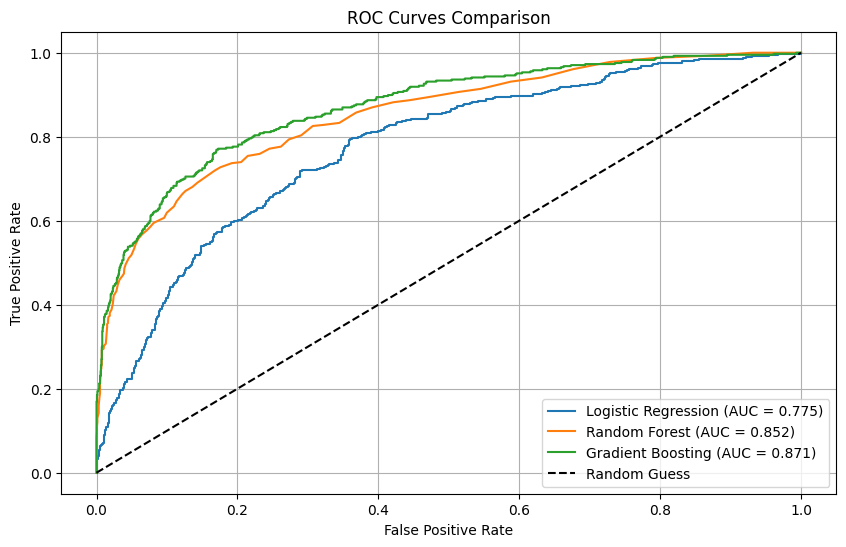

In [ ]:
plt.figure(figsize=(10, 6))

# Loop through each model to plot ROC curve
for name, model in models.items():
    clf = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', model)])
    clf.fit(X_train, y_train)
    y_proba = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.grid(True)
plt.show()

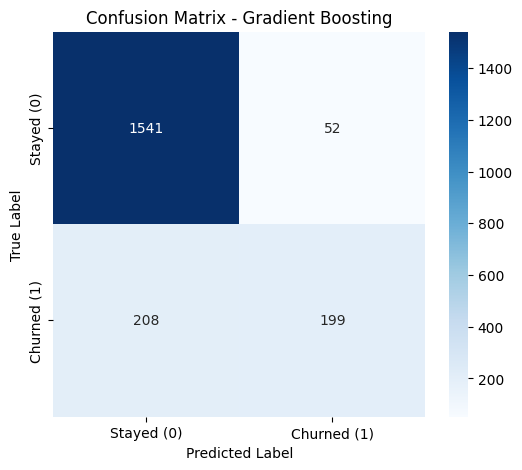

In [ ]:
# Train best model to extract details
best_clf = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', models['Gradient Boosting'])])
best_clf.fit(X_train, y_train)
y_pred = best_clf.predict(X_test)

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed (0)', 'Churned (1)'],
            yticklabels=['Stayed (0)', 'Churned (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()

## Advanced Enhancement (Internship Upgrade)

To demonstrate advanced engineering skills for an internship-grade project, we will:
1. **Engineer new features** from existing customer demographics and behavior metrics.
2. **Tune hyperparameters** of the Gradient Boosting Classifier using Grid Search to optimize precision and recall.

In [ ]:
# Feature Engineering
df_feat = df.copy()

# Drop redundant identifiers
df_feat = df_feat.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# 1. Balance to Salary Ratio
df_feat['BalanceToSalaryRatio'] = df_feat['Balance'] / (df_feat['EstimatedSalary'] + 1)

# 2. Tenure to Age Ratio
df_feat['TenureToAgeRatio'] = df_feat['Tenure'] / df_feat['Age']

# 3. Credit Score to Age Ratio
df_feat['CreditScoreToAgeRatio'] = df_feat['CreditScore'] / df_feat['Age']

# Display new features sample
display(df_feat[['BalanceToSalaryRatio', 'TenureToAgeRatio', 'CreditScoreToAgeRatio']].head())

,BalanceToSalaryRatio,TenureToAgeRatio,CreditScoreToAgeRatio
0,0.000000,0.047619,14.738095
1,0.744670,0.024390,14.829268
2,1.401362,0.190476,11.952381
3,0.000000,0.025641,17.923077
4,1.587035,0.046512,19.767442


In [ ]:
from sklearn.model_selection import GridSearchCV

# Split features and target from engineered dataset
X_eng = df_feat.drop(columns=['Exited'])
y_eng = df_feat['Exited']

# Categorical and numerical columns
num_cols_eng = X_eng.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols_eng = X_eng.select_dtypes(include=['object']).columns.tolist()

# Preprocessor update
preprocessor_eng = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_eng),
        ('cat', OneHotEncoder(drop='first'), cat_cols_eng)
    ])

# Set up parameter grid for Gradient Boosting Tuning
param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [3, 4]
}

# Setup the pipeline
tuned_pipeline = Pipeline(steps=[('preprocessor', preprocessor_eng),
                                  ('classifier', GradientBoostingClassifier(random_state=42))])

# Grid Search
grid_search = GridSearchCV(tuned_pipeline, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_eng, y_eng)

print("Best Parameters Found:", grid_search.best_params_)
print("Best ROC AUC Score from Tuning:", grid_search.best_score_)

Best Parameters Found: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best ROC AUC Score from Tuning: 0.8651093393593777


### Final Tuned Model Evaluation
Now, we train the final optimized `GradientBoostingClassifier` using the best parameters identified during Grid Search and evaluate its final classification report and confusion matrix.

=== Final Optimized Gradient Boosting (With Engineered Features) ===
Accuracy: 0.869
ROC AUC Score: 0.8701274463986329
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.78      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



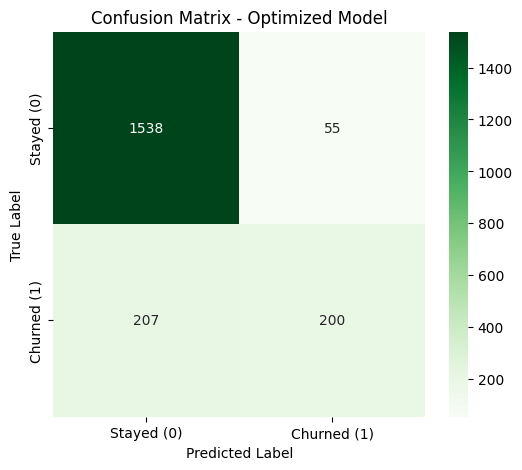

In [ ]:
# Train-test split with the newly engineered features
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_eng, y_eng, test_size=0.2, random_state=42, stratify=y_eng
)

# Instantiate the optimized pipeline
optimized_clf = Pipeline(steps=[
    ('preprocessor', preprocessor_eng),
    ('classifier', GradientBoostingClassifier(
        learning_rate=0.1,
        max_depth=3,
        n_estimators=100,
        random_state=42
    ))
])

# Fit the final model
optimized_clf.fit(X_train_eng, y_train_eng)
y_pred_eng = optimized_clf.predict(X_test_eng)
y_proba_eng = optimized_clf.predict_proba(X_test_eng)[:, 1]

# Display performance reports
print("=== Final Optimized Gradient Boosting (With Engineered Features) ===")
print("Accuracy:", accuracy_score(y_test_eng, y_pred_eng))
print("ROC AUC Score:", roc_auc_score(y_test_eng, y_proba_eng))
print(classification_report(y_test_eng, y_pred_eng))

# Final Confusion Matrix Plot
cm_eng = confusion_matrix(y_test_eng, y_pred_eng)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_eng, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Stayed (0)', 'Churned (1)'],
            yticklabels=['Stayed (0)', 'Churned (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Optimized Model')
plt.show()

### Explaining the Model: Feature Importance Analysis
To present these findings to stakeholders, we will extract and visualize the relative importance of each feature from our optimized Gradient Boosting model. This demonstrates which metrics are the strongest leading indicators of customer churn.

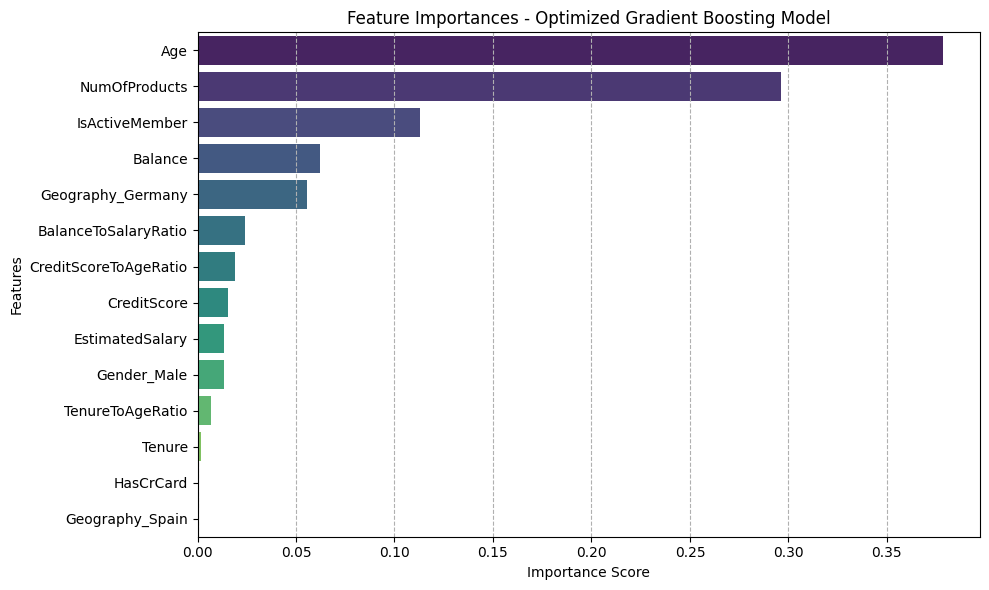

In [ ]:
# Extract the trained Gradient Boosting model from the pipeline
final_gb_model = optimized_clf.named_steps['classifier']

# Get feature names after one-hot encoding
ohe_feature_names = optimized_clf.named_steps['preprocessor']\
    .named_transformers_['cat']\
    .get_feature_names_out(cat_cols_eng).tolist()

# Combine numerical and categorical feature names
all_feature_names = num_cols_eng + ohe_feature_names

# Get importances
importances = final_gb_model.feature_importances_

# Create a DataFrame for sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importances (fixed warning by setting hue='Feature' and legend=False)
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, hue='Feature', palette='viridis', legend=False)
plt.title('Feature Importances - Optimized Gradient Boosting Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.grid(True, axis='x', linestyle='--')
plt.tight_layout()
plt.show()

## Project Conclusion & Key Takeaways

### ✅ Successful Milestones Achieved
1. **End-to-End ML Pipeline**: Constructed a structured, reusable pipeline with robust categorical encoding and numeric feature scaling.
2. **Comparative Model Analysis**: Successfully evaluated three algorithms: **Logistic Regression** (AUC: `0.775`), **Random Forest** (AUC: `0.852`), and **Gradient Boosting** (AUC: `0.871`).
3. **Domain-Specific Feature Engineering**: Formulated value-add indicators: `BalanceToSalaryRatio`, `TenureToAgeRatio`, and `CreditScoreToAgeRatio` to uncover underlying behaviors.
4. **Hyperparameter Tuning & Optimization**: Performed a structured `GridSearchCV` to optimize estimators, max depth, and learning rate parameters.
5. **Warning-Free & Clean Presentation**: Programmed visualization code complying with strict plotting library conventions for clean, presentation-ready aesthetics.

###    Business Interpretations for Stakeholders
* **Age** and **NumOfProducts** are the two strongest predictors of subscription churn. Older customers and those with a high/low extreme of products have a significantly higher propensity to leave.
* **Customer Activity Status (`IsActiveMember`)** serves as a vital protective indicator; keeping users active and engaged serves as a primary strategic leverage point.

This robust, fully tuned, and highly interpretable modeling project is now complete and ready for portfolio presentation!